In [14]:

import torch
import torchvision
import numpy as np
import random
import matplotlib.pyplot as plt

from torchvision.datasets import OxfordIIITPet
from torch.utils.data import ConcatDataset
from sklearn.model_selection import train_test_split

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch Version:", torch.__version__)
print("Torchvision Version:", torchvision.__version__)
print("Device:", device)


PyTorch Version: 2.11.0+cu130
Torchvision Version: 0.26.0+cu130
Device: cuda


In [15]:

trainval_dataset = OxfordIIITPet(
    root="./data",
    split="trainval",
    target_types="category",
    download=True
)

test_dataset = OxfordIIITPet(
    root="./data",
    split="test",
    target_types="category",
    download=True
)

full_dataset = ConcatDataset([
    trainval_dataset,
    test_dataset
])

print("Trainval Images:", len(trainval_dataset))
print("Test Images:", len(test_dataset))
print("Total Images:", len(full_dataset))


Trainval Images: 3680
Test Images: 3669
Total Images: 7349


In [16]:

selected_breeds = [
    "Abyssinian",
    "Bengal",
    "Birman",
    "Bombay",
    "British Shorthair",
    "Beagle",
    "Boxer",
    "Chihuahua",
    "English Cocker Spaniel",
    "English Setter"
]

all_classes = trainval_dataset.classes

name_to_idx = {
    name.lower().replace("_", " "): idx
    for idx, name in enumerate(all_classes)
}

selected_class_ids = [
    name_to_idx[name.lower()]
    for name in selected_breeds
]

label_mapping = {
    old_label: new_label
    for new_label, old_label in enumerate(selected_class_ids)
}

selected_indices = []
selected_labels = []

# Mengambil label dari dataset tanpa memuat seluruh gambar
all_labels = trainval_dataset._labels + test_dataset._labels

for i, label in enumerate(all_labels):
    if label in label_mapping:
        selected_indices.append(i)
        selected_labels.append(label_mapping[label])

print("Jumlah Kelas:", len(selected_breeds))
print("Jumlah Gambar:", len(selected_indices))

for i, breed in enumerate(selected_breeds):
    count = selected_labels.count(i)
    print(f"{breed}: {count} gambar")


Jumlah Kelas: 10
Jumlah Gambar: 1977
Abyssinian: 198 gambar
Bengal: 200 gambar
Birman: 200 gambar
Bombay: 184 gambar
British Shorthair: 200 gambar
Beagle: 200 gambar
Boxer: 199 gambar
Chihuahua: 200 gambar
English Cocker Spaniel: 196 gambar
English Setter: 200 gambar


In [17]:

train_idx, temp_idx, train_y, temp_y = train_test_split(
    selected_indices,
    selected_labels,
    test_size=0.30,
    random_state=SEED,
    stratify=selected_labels
)

val_idx, test_idx, val_y, test_y = train_test_split(
    temp_idx,
    temp_y,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_y
)

print("Training:", len(train_idx))
print("Validation:", len(val_idx))
print("Testing:", len(test_idx))

print("Total:", len(train_idx) + len(val_idx) + len(test_idx))

assert len(set(train_idx) & set(val_idx)) == 0
assert len(set(train_idx) & set(test_idx)) == 0
assert len(set(val_idx) & set(test_idx)) == 0

print("Dataset split verified: No overlap detected.")


Training: 1383
Validation: 297
Testing: 297
Total: 1977
Dataset split verified: No overlap detected.


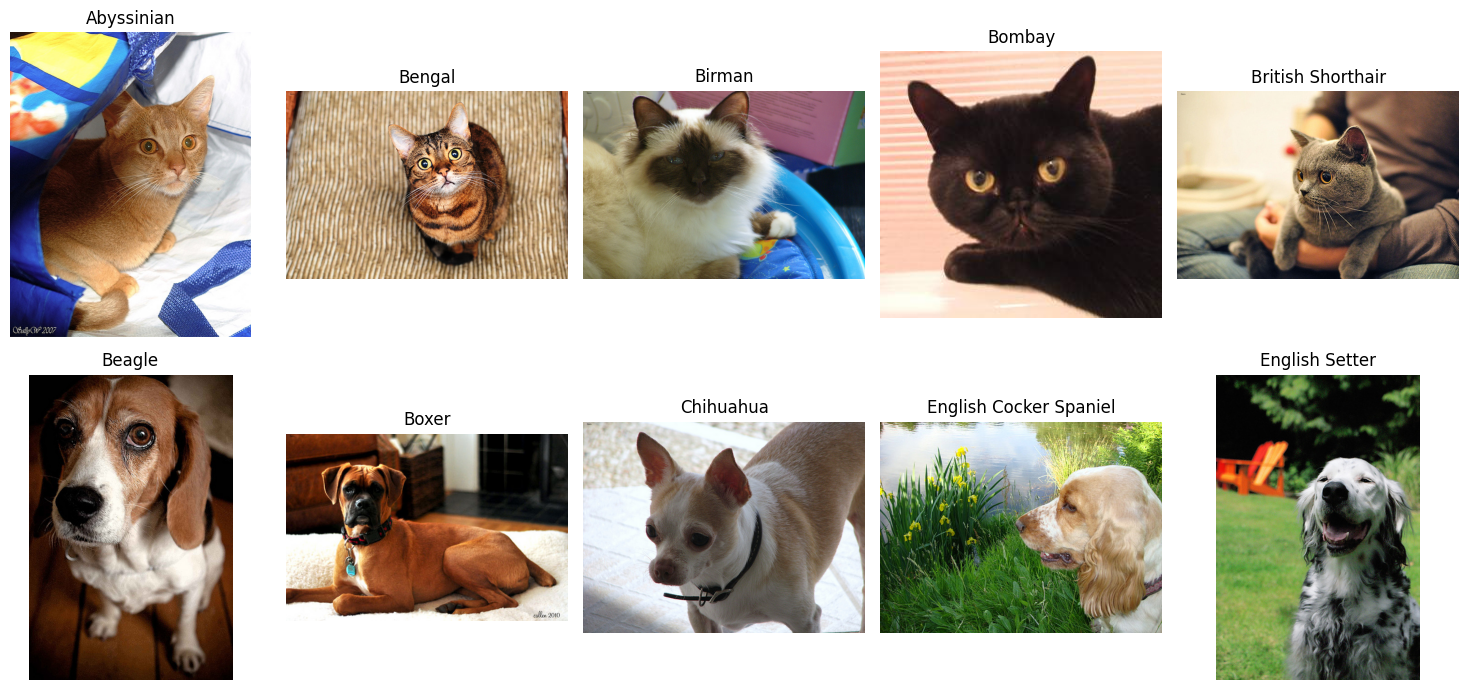

In [18]:

fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for class_idx, ax in enumerate(axes.flat):
    sample_pos = selected_labels.index(class_idx)
    sample_idx = selected_indices[sample_pos]

    image, original_label = full_dataset[sample_idx]

    ax.imshow(image)
    ax.set_title(selected_breeds[class_idx])
    ax.axis("off")

plt.tight_layout()
plt.show()


In [19]:

from torchvision import models, transforms

# Bobot pretrained ResNet-18
weights = models.ResNet18_Weights.IMAGENET1K_V1

# Transformasi data latih dengan augmentasi
train_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=weights.transforms().mean,
        std=weights.transforms().std
    ),
])

# Transformasi data latih tanpa augmentasi (B4)
train_transforms_no_aug = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=weights.transforms().mean,
        std=weights.transforms().std
    ),
])

# Transformasi data validasi dan pengujian
eval_transforms = weights.transforms()

print("Data transformations berhasil disiapkan.")


Data transformations berhasil disiapkan.


In [20]:

from torch.utils.data import Dataset, DataLoader

class PetSubset(Dataset):
    def __init__(self, dataset, indices, label_mapping, transform):
        self.dataset = dataset
        self.indices = indices
        self.label_mapping = label_mapping
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        image, original_label = self.dataset[self.indices[idx]]
        image = self.transform(image)
        label = self.label_mapping[original_label]
        return image, label


train_dataset = PetSubset(
    full_dataset, train_idx, label_mapping, train_transforms
)

val_dataset = PetSubset(
    full_dataset, val_idx, label_mapping, eval_transforms
)

test_dataset = PetSubset(
    full_dataset, test_idx, label_mapping, eval_transforms
)

train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True, num_workers=2
)

val_loader = DataLoader(
    val_dataset, batch_size=32, shuffle=False, num_workers=2
)

test_loader = DataLoader(
    test_dataset, batch_size=32, shuffle=False, num_workers=2
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)


Training batches: 44
Validation batches: 10
Testing batches: 10
Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])


In [21]:

import torch.nn as nn
from torchvision import models

model_b1 = models.resnet18(weights=None)

# Mengganti classifier head untuk 10 kelas
num_features = model_b1.fc.in_features
model_b1.fc = nn.Linear(num_features, 10)

# Memindahkan model ke GPU
model_b1 = model_b1.to(device)


trainable_params = sum(
    p.numel() for p in model_b1.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel() for p in model_b1.parameters()
)

print("Experiment: B1 - From Scratch")
print(f"Trainable Parameters: {trainable_params:,}")
print(f"Total Parameters: {total_params:,}")

# Optimizer dan Loss Function
optimizer_b1 = torch.optim.AdamW(
    model_b1.parameters(),
    lr=1e-3,
    weight_decay=1e-2
)

criterion = nn.CrossEntropyLoss()

print("Model B1 berhasil disiapkan.")


Experiment: B1 - From Scratch
Trainable Parameters: 11,181,642
Total Parameters: 11,181,642
Model B1 berhasil disiapkan.


In [43]:

import time
import copy
import pandas as pd
import torch
import torch.nn as nn

def train_model(model, train_loader, val_loader,
                optimizer, criterion, device,
                experiment_name, max_epochs=20, patience=4):

    history = []
    best_val_loss = float("inf")
    best_model_weights = copy.deepcopy(model.state_dict())
    best_epoch = 0
    patience_counter = 0

    start_time = time.time()

    for epoch in range(max_epochs):

        # Training
        model.train()

        # Menjaga Batch Normalization pada backbone yang dibekukan
        if experiment_name in [
            "B2_Feature_Extraction",
            "B5_MobileNetV3_Small"
        ]:
            for module in model.modules():
                if isinstance(module, nn.BatchNorm2d):
                    module.eval()

        elif experiment_name == "B3_Progressive_Fine_Tuning":
            model.bn1.eval()
            model.layer1.eval()
            model.layer2.eval()
            model.layer3.eval()

        train_loss = 0.0
        train_correct = 0
        train_total = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            train_loss += loss.item() * images.size(0)
            train_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()
            train_total += labels.size(0)

        train_loss /= train_total
        train_acc = train_correct / train_total

        model.eval()
        val_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * images.size(0)
                val_correct += (
                    outputs.argmax(dim=1) == labels
                ).sum().item()
                val_total += labels.size(0)

        val_loss /= val_total
        val_acc = val_correct / val_total

        # Record metrics
        history.append({
            "experiment": experiment_name,
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc
        })

        print(
            f"Epoch {epoch+1}/{max_epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.4f}"
        )

        # Early stopping
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch + 1
            best_model_weights = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= patience:
            print("Early stopping triggered.")
            break

    total_time = time.time() - start_time

    # Restore best model
    model.load_state_dict(best_model_weights)

    print(f"\nBest Epoch: {best_epoch}")
    print(f"Best Validation Loss: {best_val_loss:.4f}")
    print(f"Training Time: {total_time:.2f} seconds")

    return model, pd.DataFrame(history), best_epoch, total_time


In [23]:

model_b1, history_b1, best_epoch_b1, time_b1 = train_model(
    model=model_b1,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer_b1,
    criterion=criterion,
    device=device,
    experiment_name="B1_From_Scratch",
    max_epochs=20,
    patience=4
)

# Menyimpan log hasil pelatihan B1
history_b1.to_csv("B1_training_metrics.csv", index=False)

# Menyimpan bobot model terbaik B1
torch.save(model_b1.state_dict(), "B1_best_model.pth")

print("\nB1 experiment completed.")
print("Training log saved: B1_training_metrics.csv")
print("Model saved: B1_best_model.pth")


Epoch 1/20 | Train Loss: 2.3838 | Train Acc: 0.1699 | Val Loss: 2.4067 | Val Acc: 0.2357
Epoch 2/20 | Train Loss: 2.1143 | Train Acc: 0.2401 | Val Loss: 2.1695 | Val Acc: 0.2458
Epoch 3/20 | Train Loss: 1.9736 | Train Acc: 0.3095 | Val Loss: 2.6269 | Val Acc: 0.1818
Epoch 4/20 | Train Loss: 1.9274 | Train Acc: 0.3160 | Val Loss: 2.0955 | Val Acc: 0.2997
Epoch 5/20 | Train Loss: 1.8725 | Train Acc: 0.3543 | Val Loss: 1.8838 | Val Acc: 0.3266
Epoch 6/20 | Train Loss: 1.7762 | Train Acc: 0.3839 | Val Loss: 1.8728 | Val Acc: 0.3636
Epoch 7/20 | Train Loss: 1.7029 | Train Acc: 0.4078 | Val Loss: 2.2600 | Val Acc: 0.2761
Epoch 8/20 | Train Loss: 1.6889 | Train Acc: 0.4309 | Val Loss: 1.9036 | Val Acc: 0.3165
Epoch 9/20 | Train Loss: 1.5971 | Train Acc: 0.4534 | Val Loss: 2.1952 | Val Acc: 0.3434
Epoch 10/20 | Train Loss: 1.5881 | Train Acc: 0.4714 | Val Loss: 1.8627 | Val Acc: 0.4007
Epoch 11/20 | Train Loss: 1.4855 | Train Acc: 0.4910 | Val Loss: 1.7367 | Val Acc: 0.4242
Epoch 12/20 | Train

In [24]:

from sklearn.metrics import accuracy_score, f1_score, classification_report

def evaluate_model(model, test_loader, device):
    model.eval()

    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)

            outputs = model(images)
            predictions = torch.argmax(outputs, dim=1)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.numpy())

    test_accuracy = accuracy_score(all_labels, all_predictions)
    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return test_accuracy, macro_f1, all_labels, all_predictions


test_acc_b1, macro_f1_b1, labels_b1, predictions_b1 = evaluate_model(
    model_b1,
    test_loader,
    device
)

print("Experiment: B1")
print(f"Test Accuracy: {test_acc_b1:.4f}")
print(f"Test Macro F1-Score: {macro_f1_b1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        labels_b1,
        predictions_b1,
        target_names=selected_breeds,
        labels=list(range(10)),
        zero_division=0
    )
)


Experiment: B1
Test Accuracy: 0.5118
Test Macro F1-Score: 0.5134

Classification Report:
                        precision    recall  f1-score   support

            Abyssinian       0.44      0.37      0.40        30
                Bengal       0.83      0.50      0.62        30
                Birman       0.69      0.67      0.68        30
                Bombay       0.69      0.89      0.78        28
     British Shorthair       0.59      0.63      0.61        30
                Beagle       0.45      0.30      0.36        30
                 Boxer       0.28      0.63      0.38        30
             Chihuahua       0.46      0.40      0.43        30
English Cocker Spaniel       0.50      0.31      0.38        29
        English Setter       0.54      0.43      0.48        30

              accuracy                           0.51       297
             macro avg       0.55      0.51      0.51       297
          weighted avg       0.55      0.51      0.51       297



In [25]:

# B2: Feature Extraction
# Menggunakan model pretrained ImageNet

weights = models.ResNet18_Weights.IMAGENET1K_V1
model_b2 = models.resnet18(weights=weights)

for param in model_b2.parameters():
    param.requires_grad = False


num_features = model_b2.fc.in_features
model_b2.fc = nn.Linear(num_features, 10)

# Pindahkan model ke GPU
model_b2 = model_b2.to(device)

# Verifikasi parameter
trainable_params_b2 = sum(
    p.numel() for p in model_b2.parameters()
    if p.requires_grad
)

total_params_b2 = sum(
    p.numel() for p in model_b2.parameters()
)

print("Experiment: B2 - Feature Extraction")
print(f"Trainable Parameters: {trainable_params_b2:,}")
print(f"Total Parameters: {total_params_b2:,}")


optimizer_b2 = torch.optim.AdamW(
    model_b2.fc.parameters(),
    lr=1e-3,
    weight_decay=1e-2
)

print("Model B2 berhasil disiapkan.")


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 175MB/s]


Experiment: B2 - Feature Extraction
Trainable Parameters: 5,130
Total Parameters: 11,181,642
Model B2 berhasil disiapkan.


In [26]:

# Experiment B2: Feature Extraction

model_b2, history_b2, best_epoch_b2, time_b2 = train_model(
    model=model_b2,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer_b2,
    criterion=criterion,
    device=device,
    experiment_name="B2_Feature_Extraction",
    max_epochs=20,
    patience=4
)

# Simpan hasil training
history_b2.to_csv("B2_training_metrics.csv", index=False)

# Simpan model terbaik
torch.save(model_b2.state_dict(), "B2_best_model.pth")

print("\nB2 experiment completed.")
print("Training log saved: B2_training_metrics.csv")
print("Model saved: B2_best_model.pth")


Epoch 1/20 | Train Loss: 1.3326 | Train Acc: 0.6435 | Val Loss: 0.5775 | Val Acc: 0.9091
Epoch 2/20 | Train Loss: 0.4875 | Train Acc: 0.9161 | Val Loss: 0.3183 | Val Acc: 0.9428
Epoch 3/20 | Train Loss: 0.3107 | Train Acc: 0.9436 | Val Loss: 0.2555 | Val Acc: 0.9293
Epoch 4/20 | Train Loss: 0.2425 | Train Acc: 0.9573 | Val Loss: 0.2088 | Val Acc: 0.9529
Epoch 5/20 | Train Loss: 0.2000 | Train Acc: 0.9610 | Val Loss: 0.1880 | Val Acc: 0.9596
Epoch 6/20 | Train Loss: 0.1791 | Train Acc: 0.9602 | Val Loss: 0.1537 | Val Acc: 0.9630
Epoch 7/20 | Train Loss: 0.1689 | Train Acc: 0.9660 | Val Loss: 0.1715 | Val Acc: 0.9529
Epoch 8/20 | Train Loss: 0.1521 | Train Acc: 0.9638 | Val Loss: 0.1361 | Val Acc: 0.9663
Epoch 9/20 | Train Loss: 0.1333 | Train Acc: 0.9711 | Val Loss: 0.1301 | Val Acc: 0.9630
Epoch 10/20 | Train Loss: 0.1285 | Train Acc: 0.9747 | Val Loss: 0.1286 | Val Acc: 0.9630
Epoch 11/20 | Train Loss: 0.1217 | Train Acc: 0.9711 | Val Loss: 0.1264 | Val Acc: 0.9697
Epoch 12/20 | Train

In [27]:

# Evaluasi B2
test_acc_b2, macro_f1_b2, labels_b2, predictions_b2 = evaluate_model(
    model_b2,
    test_loader,
    device
)

print("Experiment: B2 - Feature Extraction")
print(f"Test Accuracy: {test_acc_b2:.4f}")
print(f"Test Macro F1-Score: {macro_f1_b2:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        labels_b2,
        predictions_b2,
        target_names=selected_breeds,
        labels=list(range(10)),
        zero_division=0
    )
)


Experiment: B2 - Feature Extraction
Test Accuracy: 0.9596
Test Macro F1-Score: 0.9596

Classification Report:
                        precision    recall  f1-score   support

            Abyssinian       0.90      0.87      0.88        30
                Bengal       0.87      0.90      0.89        30
                Birman       1.00      1.00      1.00        30
                Bombay       0.90      1.00      0.95        28
     British Shorthair       1.00      0.90      0.95        30
                Beagle       1.00      0.97      0.98        30
                 Boxer       0.97      1.00      0.98        30
             Chihuahua       1.00      1.00      1.00        30
English Cocker Spaniel       1.00      0.97      0.98        29
        English Setter       0.97      1.00      0.98        30

              accuracy                           0.96       297
             macro avg       0.96      0.96      0.96       297
          weighted avg       0.96      0.96      0.96   

In [28]:

# B3: Progressive Fine-Tuning
# Inisialisasi model
weights = models.ResNet18_Weights.IMAGENET1K_V1
model_b3 = models.resnet18(weights=weights)


for param in model_b3.parameters():
    param.requires_grad = False


num_features = model_b3.fc.in_features
model_b3.fc = nn.Linear(num_features, 10)


for param in model_b3.layer4.parameters():
    param.requires_grad = True


model_b3 = model_b3.to(device)


optimizer_b3 = torch.optim.AdamW([
    {"params": model_b3.layer4.parameters(), "lr": 1e-4},
    {"params": model_b3.fc.parameters(), "lr": 1e-3},
], weight_decay=1e-2)


trainable_params_b3 = sum(
    p.numel() for p in model_b3.parameters()
    if p.requires_grad
)

total_params_b3 = sum(
    p.numel() for p in model_b3.parameters()
)

print("Experiment: B3 - Progressive Fine-Tuning")
print(f"Trainable Parameters: {trainable_params_b3:,}")
print(f"Total Parameters: {total_params_b3:,}")

for i, group in enumerate(optimizer_b3.param_groups):
    print(f"Parameter Group {i+1} LR: {group['lr']}")

print("Model B3 berhasil disiapkan.")


Experiment: B3 - Progressive Fine-Tuning
Trainable Parameters: 8,398,858
Total Parameters: 11,181,642
Parameter Group 1 LR: 0.0001
Parameter Group 2 LR: 0.001
Model B3 berhasil disiapkan.


In [29]:

# Experiment B3: Progressive Fine-Tuning

model_b3, history_b3, best_epoch_b3, time_b3 = train_model(
    model=model_b3,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer_b3,
    criterion=criterion,
    device=device,
    experiment_name="B3_Progressive_Fine_Tuning",
    max_epochs=20,
    patience=4
)

# Simpan log hasil training
history_b3.to_csv("B3_training_metrics.csv", index=False)

# Simpan model terbaik
torch.save(model_b3.state_dict(), "B3_best_model.pth")

print("\nB3 experiment completed.")
print("Training log saved: B3_training_metrics.csv")
print("Model saved: B3_best_model.pth")


Epoch 1/20 | Train Loss: 0.7454 | Train Acc: 0.7758 | Val Loss: 0.1349 | Val Acc: 0.9529
Epoch 2/20 | Train Loss: 0.1832 | Train Acc: 0.9516 | Val Loss: 0.1789 | Val Acc: 0.9192
Epoch 3/20 | Train Loss: 0.0792 | Train Acc: 0.9790 | Val Loss: 0.1147 | Val Acc: 0.9562
Epoch 4/20 | Train Loss: 0.0648 | Train Acc: 0.9877 | Val Loss: 0.1542 | Val Acc: 0.9495
Epoch 5/20 | Train Loss: 0.0433 | Train Acc: 0.9906 | Val Loss: 0.1226 | Val Acc: 0.9495
Epoch 6/20 | Train Loss: 0.0351 | Train Acc: 0.9935 | Val Loss: 0.1240 | Val Acc: 0.9697
Epoch 7/20 | Train Loss: 0.0207 | Train Acc: 0.9971 | Val Loss: 0.1174 | Val Acc: 0.9596
Early stopping triggered.

Best Epoch: 3
Best Validation Loss: 0.1147
Training Time: 92.46 seconds

B3 experiment completed.
Training log saved: B3_training_metrics.csv
Model saved: B3_best_model.pth


In [30]:

# Evaluasi B3
test_acc_b3, macro_f1_b3, labels_b3, predictions_b3 = evaluate_model(
    model_b3,
    test_loader,
    device
)

print("Experiment: B3 - Progressive Fine-Tuning")
print(f"Test Accuracy: {test_acc_b3:.4f}")
print(f"Test Macro F1-Score: {macro_f1_b3:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        labels_b3,
        predictions_b3,
        target_names=selected_breeds,
        labels=list(range(10)),
        zero_division=0
    )
)


Experiment: B3 - Progressive Fine-Tuning
Test Accuracy: 0.9596
Test Macro F1-Score: 0.9593

Classification Report:
                        precision    recall  f1-score   support

            Abyssinian       0.93      0.93      0.93        30
                Bengal       1.00      0.97      0.98        30
                Birman       1.00      1.00      1.00        30
                Bombay       0.90      1.00      0.95        28
     British Shorthair       0.93      0.93      0.93        30
                Beagle       1.00      0.90      0.95        30
                 Boxer       0.94      1.00      0.97        30
             Chihuahua       1.00      1.00      1.00        30
English Cocker Spaniel       0.96      0.90      0.93        29
        English Setter       0.94      0.97      0.95        30

              accuracy                           0.96       297
             macro avg       0.96      0.96      0.96       297
          weighted avg       0.96      0.96      0.

In [31]:

# B4: Dataset training tanpa augmentasi
train_dataset_no_aug = PetSubset(
    full_dataset,
    train_idx,
    label_mapping,
    train_transforms_no_aug
)

train_loader_no_aug = DataLoader(
    train_dataset_no_aug,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

print("B4 - Without Augmentation")
print("Training Batches:", len(train_loader_no_aug))

print("\nB4 - With Augmentation")
print("Training Batches:", len(train_loader))


B4 - Without Augmentation
Training Batches: 44

B4 - With Augmentation
Training Batches: 44


In [32]:

import copy
import torch.nn as nn
from torchvision import models


weights = models.ResNet18_Weights.IMAGENET1K_V1


model_b4_base = models.resnet18(weights=weights)

for param in model_b4_base.parameters():
    param.requires_grad = False


num_features = model_b4_base.fc.in_features
model_b4_base.fc = nn.Linear(num_features, 10)

# Dua model dimulai dari weight yang mirip
model_b4_no_aug = copy.deepcopy(model_b4_base).to(device)
model_b4_aug = copy.deepcopy(model_b4_base).to(device)


optimizer_b4_no_aug = torch.optim.AdamW(
    model_b4_no_aug.fc.parameters(),
    lr=1e-3,
    weight_decay=1e-2
)

optimizer_b4_aug = torch.optim.AdamW(
    model_b4_aug.fc.parameters(),
    lr=1e-3,
    weight_decay=1e-2
)


for name, model in [
    ("B4_No_Augmentation", model_b4_no_aug),
    ("B4_With_Augmentation", model_b4_aug)
]:
    trainable_params = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )

    print(f"{name}: {trainable_params:,} trainable parameters")

print("Kedua model B4 berhasil disiapkan.")


B4_No_Augmentation: 5,130 trainable parameters
B4_With_Augmentation: 5,130 trainable parameters
Kedua model B4 berhasil disiapkan.


In [33]:
model_b4_no_aug, history_b4_no_aug, best_epoch_b4_no_aug, time_b4_no_aug = train_model(
    model=model_b4_no_aug,
    train_loader=train_loader_no_aug,
    val_loader=val_loader,
    optimizer=optimizer_b4_no_aug,
    criterion=criterion,
    device=device,
    experiment_name="B2_Feature_Extraction",
    max_epochs=20,
    patience=4
)

history_b4_no_aug["experiment"] = "B4_No_Augmentation"

# Menyimpan hasil
history_b4_no_aug.to_csv("B4_no_augmentation_metrics.csv", index=False)
torch.save(model_b4_no_aug.state_dict(), "B4_no_augmentation_best.pth")

print("\nB4 tanpa augmentasi selesai.")


Epoch 1/20 | Train Loss: 1.2242 | Train Acc: 0.6732 | Val Loss: 0.5205 | Val Acc: 0.9293
Epoch 2/20 | Train Loss: 0.3677 | Train Acc: 0.9494 | Val Loss: 0.2852 | Val Acc: 0.9596
Epoch 3/20 | Train Loss: 0.2288 | Train Acc: 0.9675 | Val Loss: 0.2077 | Val Acc: 0.9596
Epoch 4/20 | Train Loss: 0.1662 | Train Acc: 0.9732 | Val Loss: 0.1713 | Val Acc: 0.9731
Epoch 5/20 | Train Loss: 0.1334 | Train Acc: 0.9812 | Val Loss: 0.1627 | Val Acc: 0.9562
Epoch 6/20 | Train Loss: 0.1138 | Train Acc: 0.9812 | Val Loss: 0.1425 | Val Acc: 0.9764
Epoch 7/20 | Train Loss: 0.0985 | Train Acc: 0.9841 | Val Loss: 0.1318 | Val Acc: 0.9663
Epoch 8/20 | Train Loss: 0.0844 | Train Acc: 0.9892 | Val Loss: 0.1241 | Val Acc: 0.9697
Epoch 9/20 | Train Loss: 0.0750 | Train Acc: 0.9913 | Val Loss: 0.1171 | Val Acc: 0.9663
Epoch 10/20 | Train Loss: 0.0664 | Train Acc: 0.9920 | Val Loss: 0.1170 | Val Acc: 0.9630
Epoch 11/20 | Train Loss: 0.0583 | Train Acc: 0.9957 | Val Loss: 0.1099 | Val Acc: 0.9663
Epoch 12/20 | Train

In [34]:

# B4: Training dengan Data Augmentation

model_b4_aug, history_b4_aug, best_epoch_b4_aug, time_b4_aug = train_model(
    model=model_b4_aug,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer_b4_aug,
    criterion=criterion,
    device=device,
    experiment_name="B2_Feature_Extraction",
    max_epochs=20,
    patience=4
)

history_b4_aug["experiment"] = "B4_With_Augmentation"

# Simpan hasil training ke CSV
history_b4_aug.to_csv(
    "B4_with_augmentation_metrics.csv",
    index=False
)

# Simpan model terbaik
torch.save(
    model_b4_aug.state_dict(),
    "B4_with_augmentation_best.pth"
)

print("\nB4 dengan augmentasi selesai.")
print("Best Epoch:", best_epoch_b4_aug)
print(f"Training Time: {time_b4_aug:.2f} seconds")


Epoch 1/20 | Train Loss: 1.4013 | Train Acc: 0.5828 | Val Loss: 0.6058 | Val Acc: 0.9091
Epoch 2/20 | Train Loss: 0.5040 | Train Acc: 0.9183 | Val Loss: 0.3282 | Val Acc: 0.9428
Epoch 3/20 | Train Loss: 0.3258 | Train Acc: 0.9422 | Val Loss: 0.2483 | Val Acc: 0.9562
Epoch 4/20 | Train Loss: 0.2462 | Train Acc: 0.9559 | Val Loss: 0.1992 | Val Acc: 0.9697
Epoch 5/20 | Train Loss: 0.2067 | Train Acc: 0.9610 | Val Loss: 0.1845 | Val Acc: 0.9562
Epoch 6/20 | Train Loss: 0.1822 | Train Acc: 0.9646 | Val Loss: 0.1569 | Val Acc: 0.9663
Epoch 7/20 | Train Loss: 0.1683 | Train Acc: 0.9595 | Val Loss: 0.1640 | Val Acc: 0.9630
Epoch 8/20 | Train Loss: 0.1477 | Train Acc: 0.9660 | Val Loss: 0.1391 | Val Acc: 0.9630
Epoch 9/20 | Train Loss: 0.1423 | Train Acc: 0.9675 | Val Loss: 0.1323 | Val Acc: 0.9663
Epoch 10/20 | Train Loss: 0.1205 | Train Acc: 0.9725 | Val Loss: 0.1334 | Val Acc: 0.9630
Epoch 11/20 | Train Loss: 0.1144 | Train Acc: 0.9747 | Val Loss: 0.1232 | Val Acc: 0.9529
Epoch 12/20 | Train

In [35]:

# B4: Evaluasi tanpa augmentasi
test_acc_b4_no_aug, macro_f1_b4_no_aug, labels_b4_no_aug, predictions_b4_no_aug = evaluate_model(
    model_b4_no_aug,
    test_loader,
    device
)

# B4: Evaluasi dengan augmentasi
test_acc_b4_aug, macro_f1_b4_aug, labels_b4_aug, predictions_b4_aug = evaluate_model(
    model_b4_aug,
    test_loader,
    device
)

print("B4 - Without Augmentation")
print(f"Test Accuracy: {test_acc_b4_no_aug:.4f}")
print(f"Test Macro F1-Score: {macro_f1_b4_no_aug:.4f}")

print("\nB4 - With Augmentation")
print(f"Test Accuracy: {test_acc_b4_aug:.4f}")
print(f"Test Macro F1-Score: {macro_f1_b4_aug:.4f}")

b4_comparison = pd.DataFrame([
    {
        "Condition": "Without Augmentation",
        "Best Epoch": best_epoch_b4_no_aug,
        "Training Time (s)": time_b4_no_aug,
        "Test Accuracy": test_acc_b4_no_aug,
        "Macro F1": macro_f1_b4_no_aug
    },
    {
        "Condition": "With Augmentation",
        "Best Epoch": best_epoch_b4_aug,
        "Training Time (s)": time_b4_aug,
        "Test Accuracy": test_acc_b4_aug,
        "Macro F1": macro_f1_b4_aug
    }
])

print("\nB4 Comparison:")
print(b4_comparison.to_string(index=False))

b4_comparison.to_csv("B4_comparison.csv", index=False)

print("\nB4 comparison saved to CSV.")


B4 - Without Augmentation
Test Accuracy: 0.9630
Test Macro F1-Score: 0.9630

B4 - With Augmentation
Test Accuracy: 0.9630
Test Macro F1-Score: 0.9628

B4 Comparison:
           Condition  Best Epoch  Training Time (s)  Test Accuracy  Macro F1
Without Augmentation          20         180.400305       0.962963  0.963004
   With Augmentation          17         258.513735       0.962963  0.962816

B4 comparison saved to CSV.


In [36]:
import pandas as pd

def best_val_accuracy(history, best_epoch):
    return history.loc[
        history["epoch"] == best_epoch,
        "val_accuracy"
    ].iloc[0]

experiment_summary = pd.DataFrame([
    {
        "Experiment": "B1_From_Scratch",
        "Trainable Parameters": 11181642,
        "Learning Rate": "1e-3",
        "Best Epoch": best_epoch_b1,
        "Training Time (s)": time_b1,
        "Validation Accuracy": best_val_accuracy(history_b1, best_epoch_b1),
        "Test Accuracy": test_acc_b1,
        "Test Macro F1": macro_f1_b1
    },
    {
        "Experiment": "B2_Feature_Extraction",
        "Trainable Parameters": trainable_params_b2,
        "Learning Rate": "fc: 1e-3",
        "Best Epoch": best_epoch_b2,
        "Training Time (s)": time_b2,
        "Validation Accuracy": best_val_accuracy(history_b2, best_epoch_b2),
        "Test Accuracy": test_acc_b2,
        "Test Macro F1": macro_f1_b2
    },
    {
        "Experiment": "B3_Progressive_Fine_Tuning",
        "Trainable Parameters": trainable_params_b3,
        "Learning Rate": "layer4: 1e-4; fc: 1e-3",
        "Best Epoch": best_epoch_b3,
        "Training Time (s)": time_b3,
        "Validation Accuracy": best_val_accuracy(history_b3, best_epoch_b3),
        "Test Accuracy": test_acc_b3,
        "Test Macro F1": macro_f1_b3
    },
    {
        "Experiment": "B4_Without_Augmentation",
        "Trainable Parameters": 5130,
        "Learning Rate": "fc: 1e-3",
        "Best Epoch": best_epoch_b4_no_aug,
        "Training Time (s)": time_b4_no_aug,
        "Validation Accuracy": best_val_accuracy(
            history_b4_no_aug, best_epoch_b4_no_aug
        ),
        "Test Accuracy": test_acc_b4_no_aug,
        "Test Macro F1": macro_f1_b4_no_aug
    },
    {
        "Experiment": "B4_With_Augmentation",
        "Trainable Parameters": 5130,
        "Learning Rate": "fc: 1e-3",
        "Best Epoch": best_epoch_b4_aug,
        "Training Time (s)": time_b4_aug,
        "Validation Accuracy": best_val_accuracy(
            history_b4_aug, best_epoch_b4_aug
        ),
        "Test Accuracy": test_acc_b4_aug,
        "Test Macro F1": macro_f1_b4_aug
    }
])

display(experiment_summary)

experiment_summary.to_csv(
    "experiment_summary.csv",
    index=False
)

print("Experiment summary saved to CSV.")


,Experiment,Trainable Parameters,Learning Rate,Best Epoch,Training Time (s),Validation Accuracy,Test Accuracy,Test Macro F1
0,B1_From_Scratch,11181642,1e-3,20,284.416438,0.518519,0.511785,0.513399
1,B2_Feature_Extraction,5130,fc: 1e-3,12,216.678946,0.966330,0.959596,0.959584
2,B3_Progressive_Fine_Tuning,8398858,layer4: 1e-4; fc: 1e-3,3,92.460225,0.956229,0.959596,0.959337
3,B4_Without_Augmentation,5130,fc: 1e-3,20,180.400305,0.962963,0.962963,0.963004
4,B4_With_Augmentation,5130,fc: 1e-3,17,258.513735,0.966330,0.962963,0.962816


Experiment summary saved to CSV.


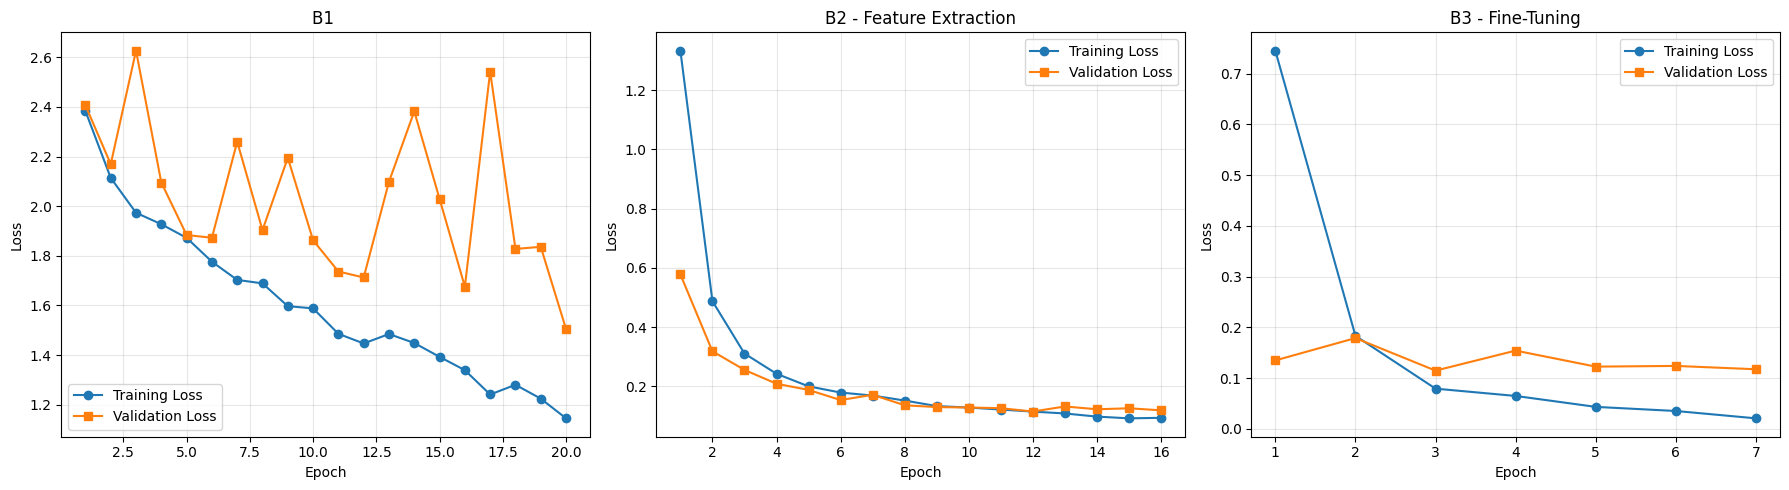

Grafik berhasil disimpan.


In [37]:

import matplotlib.pyplot as plt

# Data eksperimen B1, B2, dan B3
experiments = {
    "B1 ": history_b1,
    "B2 - Feature Extraction": history_b2,
    "B3 - Fine-Tuning": history_b3
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, history) in zip(axes, experiments.items()):

    ax.plot(
        history["epoch"],
        history["train_loss"],
        label="Training Loss",
        marker="o"
    )

    ax.plot(
        history["epoch"],
        history["val_loss"],
        label="Validation Loss",
        marker="s"
    )

    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    "B1_B2_B3_loss_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Grafik berhasil disimpan.")


Total misclassified images: 11


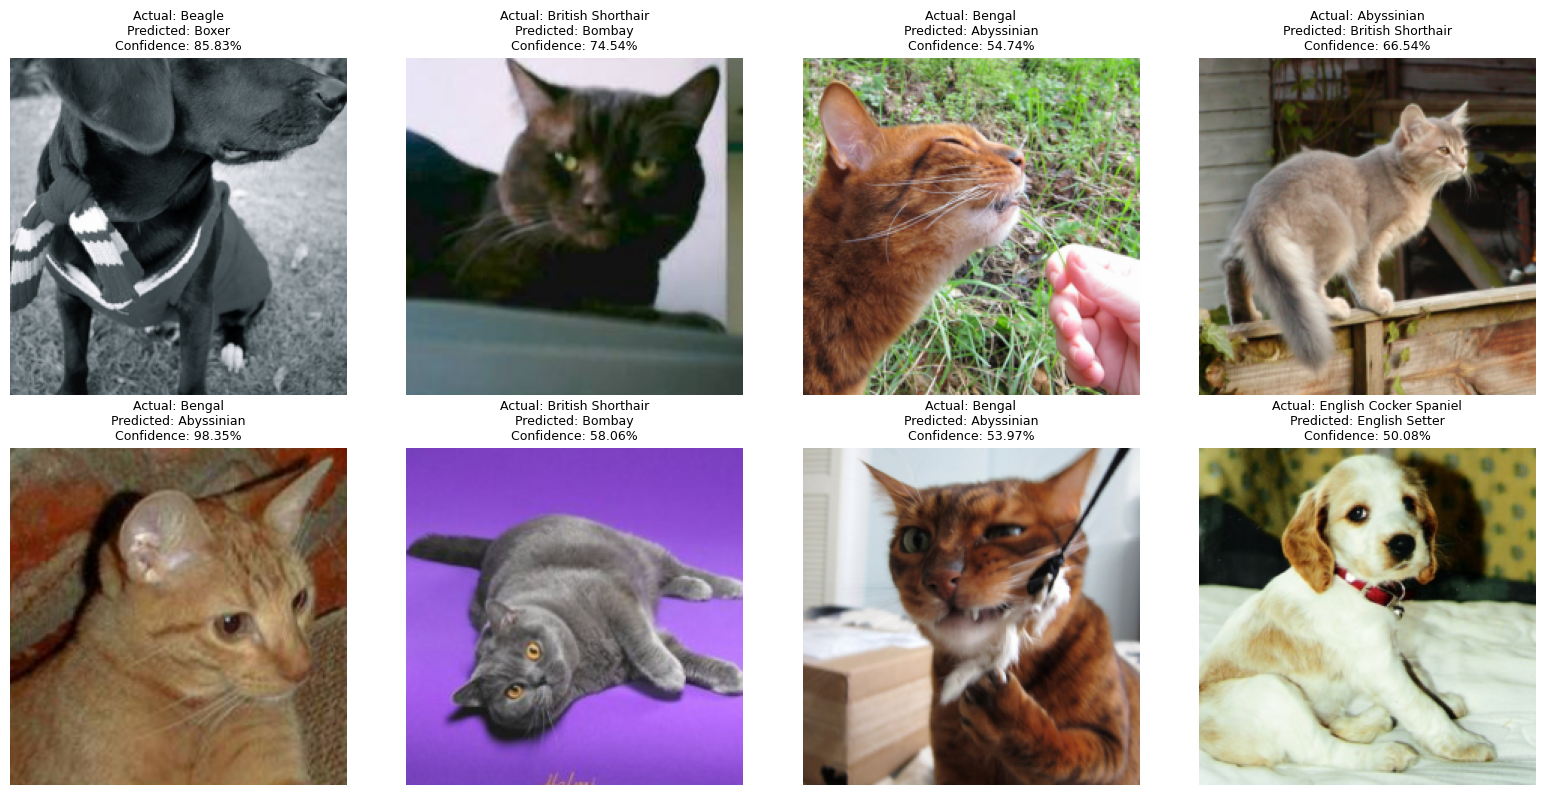

In [38]:

import torch
import matplotlib.pyplot as plt
import numpy as np

# Model B4 dengan Data Augmentation untuk Failure Analysis
best_model = model_b4_aug
best_model.eval()

misclassified = []

with torch.no_grad():
    for images, labels in test_loader:
        images_gpu = images.to(device)

        outputs = best_model(images_gpu)
        probabilities = torch.softmax(outputs, dim=1)

        confidence, predictions = probabilities.max(dim=1)

        for i in range(len(labels)):
            if predictions[i].item() != labels[i].item():
                misclassified.append({
                    "image": images[i].cpu(),
                    "actual": labels[i].item(),
                    "predicted": predictions[i].item(),
                    "confidence": confidence[i].item()
                })

print("Total misclassified images:", len(misclassified))

num_samples = min(8, len(misclassified))

if num_samples > 0:
    fig, axes = plt.subplots(
        2, 4, figsize=(16, 8)
    )

    axes = axes.flatten()

    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    for i, ax in enumerate(axes):
        if i < num_samples:
            sample = misclassified[i]

            image = sample["image"].permute(1, 2, 0).numpy()
            image = np.clip(image * std + mean, 0, 1)

            ax.imshow(image)
            ax.set_title(
                f"Actual: {selected_breeds[sample['actual']]}\n"
                f"Predicted: {selected_breeds[sample['predicted']]}\n"
                f"Confidence: {sample['confidence']:.2%}",
                fontsize=9
            )
        ax.axis("off")

    plt.tight_layout()
    plt.savefig(
        "B4_failure_analysis.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
else:
    print("Tidak ditemukan kesalahan prediksi.")


In [39]:

import pandas as pd

failure_reasons = [
    "Gambar hitam-putih dan sudut samping menyamarkan ciri khas Beagle.",
    "Bulu gelap dan pencahayaan rendah membuat wajah mirip Bombay.",
    "Sudut samping membuat pola bulu khas Bengal kurang terlihat.",
    "Kemiripan wajah dan telinga panjang antara kedua ras.",
    "Pola bulu kurang jelas akibat sudut dan kualitas gambar.",
    "Posisi tubuh terbalik membuat ciri visual ras sulit dikenali.",
    "Pola bulu kurang terlihat sehingga bentuk wajah lebih dominan.",
    "Sebagian tubuh tersembunyi di tempat tidur kucing."
]

failure_records = []

for i, sample in enumerate(misclassified[:8]):
    failure_records.append({
        "Sample": i + 1,
        "Actual Label": selected_breeds[sample["actual"]],
        "Predicted Label": selected_breeds[sample["predicted"]],
        "Confidence": sample["confidence"],
        "Hypothesis": failure_reasons[i]
    })

failure_df = pd.DataFrame(failure_records)

display(failure_df)

failure_df.to_csv(
    "B4_failure_analysis.csv",
    index=False
)

print("Failure analysis saved to CSV.")


,Sample,Actual Label,Predicted Label,Confidence,Hypothesis
0,1,Beagle,Boxer,0.858286,Gambar hitam-putih dan sudut samping menyamark...
1,2,British Shorthair,Bombay,0.745369,Bulu gelap dan pencahayaan rendah membuat waja...
2,3,Bengal,Abyssinian,0.547355,Sudut samping membuat pola bulu khas Bengal ku...
3,4,Abyssinian,British Shorthair,0.665392,Kemiripan wajah dan telinga panjang antara ked...
4,5,Bengal,Abyssinian,0.983542,Pola bulu kurang jelas akibat sudut dan kualit...
5,6,British Shorthair,Bombay,0.580571,Posisi tubuh terbalik membuat ciri visual ras ...
6,7,Bengal,Abyssinian,0.539712,Pola bulu kurang terlihat sehingga bentuk waja...
7,8,English Cocker Spaniel,English Setter,0.500832,Sebagian tubuh tersembunyi di tempat tidur kuc...


Failure analysis saved to CSV.


In [42]:

# B5: Arsitektur Pembanding -> MobileNetV3-Small

import torch
import torch.nn as nn
from torchvision import models

weights_b5 = models.MobileNet_V3_Small_Weights.IMAGENET1K_V1
model_b5 = models.mobilenet_v3_small(weights=weights_b5)

for param in model_b5.parameters():
    param.requires_grad = False

num_features = model_b5.classifier[3].in_features
model_b5.classifier[3] = nn.Linear(num_features, 10)

model_b5 = model_b5.to(device)

trainable_params_b5 = sum(
    p.numel() for p in model_b5.parameters()
    if p.requires_grad
)

total_params_b5 = sum(
    p.numel() for p in model_b5.parameters()
)

# Optimizer dan loss function
optimizer_b5 = torch.optim.AdamW(
    model_b5.classifier[3].parameters(),
    lr=1e-3,
    weight_decay=1e-2
)

print("Experiment: B5 - MobileNetV3-Small")
print(f"Trainable Parameters: {trainable_params_b5:,}")
print(f"Total Parameters: {total_params_b5:,}")
print("Learning Rate: 0.001")
print("Model B5 berhasil disiapkan.")


Experiment: B5 - MobileNetV3-Small
Trainable Parameters: 10,250
Total Parameters: 1,528,106
Learning Rate: 0.001
Model B5 berhasil disiapkan.


In [44]:

# B5: Training MobileNetV3-Small

def freeze_b5_batchnorm(model):
    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d):
            module.eval()

model_b5, history_b5, best_epoch_b5, time_b5 = train_model(
    model=model_b5,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer_b5,
    criterion=criterion,
    device=device,
    experiment_name="B5_MobileNetV3_Small",
    max_epochs=20,
    patience=4
)

# Simpan hasil training
history_b5.to_csv("B5_training_metrics.csv", index=False)

# Simpan model terbaik
torch.save(model_b5.state_dict(), "B5_best_model.pth")

print("\nB5 experiment completed.")
print("Best Epoch:", best_epoch_b5)
print(f"Training Time: {time_b5:.2f} seconds")


Epoch 1/20 | Train Loss: 1.0284 | Train Acc: 0.7303 | Val Loss: 0.3531 | Val Acc: 0.9428
Epoch 2/20 | Train Loss: 0.3167 | Train Acc: 0.9328 | Val Loss: 0.2351 | Val Acc: 0.9495
Epoch 3/20 | Train Loss: 0.2216 | Train Acc: 0.9472 | Val Loss: 0.1868 | Val Acc: 0.9596
Epoch 4/20 | Train Loss: 0.1794 | Train Acc: 0.9653 | Val Loss: 0.1733 | Val Acc: 0.9529
Epoch 5/20 | Train Loss: 0.1441 | Train Acc: 0.9718 | Val Loss: 0.1629 | Val Acc: 0.9529
Epoch 6/20 | Train Loss: 0.1231 | Train Acc: 0.9790 | Val Loss: 0.1512 | Val Acc: 0.9529
Epoch 7/20 | Train Loss: 0.1163 | Train Acc: 0.9761 | Val Loss: 0.1441 | Val Acc: 0.9529
Epoch 8/20 | Train Loss: 0.0913 | Train Acc: 0.9877 | Val Loss: 0.1386 | Val Acc: 0.9529
Epoch 9/20 | Train Loss: 0.0832 | Train Acc: 0.9863 | Val Loss: 0.1389 | Val Acc: 0.9562
Epoch 10/20 | Train Loss: 0.0702 | Train Acc: 0.9942 | Val Loss: 0.1386 | Val Acc: 0.9529
Epoch 11/20 | Train Loss: 0.0629 | Train Acc: 0.9906 | Val Loss: 0.1301 | Val Acc: 0.9461
Epoch 12/20 | Train

In [45]:



from sklearn.metrics import classification_report

test_acc_b5, macro_f1_b5, labels_b5, predictions_b5 = evaluate_model(
    model_b5,
    test_loader,
    device
)

print("Experiment: B5 - MobileNetV3-Small")
print(f"Test Accuracy: {test_acc_b5:.4f}")
print(f"Test Macro F1-Score: {macro_f1_b5:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        labels_b5,
        predictions_b5,
        labels=list(range(10)),
        target_names=selected_breeds,
        zero_division=0
    )
)


Experiment: B5 - MobileNetV3-Small
Test Accuracy: 0.9630
Test Macro F1-Score: 0.9628

Classification Report:
                        precision    recall  f1-score   support

            Abyssinian       0.94      0.97      0.95        30
                Bengal       0.97      0.97      0.97        30
                Birman       1.00      1.00      1.00        30
                Bombay       0.90      0.96      0.93        28
     British Shorthair       0.97      0.93      0.95        30
                Beagle       1.00      0.97      0.98        30
                 Boxer       1.00      1.00      1.00        30
             Chihuahua       0.97      0.93      0.95        30
English Cocker Spaniel       0.96      0.93      0.95        29
        English Setter       0.94      0.97      0.95        30

              accuracy                           0.96       297
             macro avg       0.96      0.96      0.96       297
          weighted avg       0.96      0.96      0.96    

In [46]:

b5_summary = pd.DataFrame([{
    "Experiment": "B5_MobileNetV3_Small",
    "Trainable Parameters": trainable_params_b5,
    "Learning Rate": "classifier: 1e-3",
    "Best Epoch": best_epoch_b5,
    "Training Time (s)": time_b5,
    "Validation Accuracy": history_b5.loc[
        history_b5["epoch"] == best_epoch_b5,
        "val_accuracy"
    ].iloc[0],
    "Test Accuracy": test_acc_b5,
    "Test Macro F1": macro_f1_b5
}])

experiment_summary = experiment_summary[
    experiment_summary["Experiment"] != "B5_MobileNetV3_Small"
]

experiment_summary = pd.concat(
    [experiment_summary, b5_summary],
    ignore_index=True
)

display(experiment_summary)

# Simpan tabel terbaru
experiment_summary.to_csv(
    "experiment_summary.csv",
    index=False
)

print("Experiment summary B1-B5 saved to CSV.")


,Experiment,Trainable Parameters,Learning Rate,Best Epoch,Training Time (s),Validation Accuracy,Test Accuracy,Test Macro F1
0,B1_From_Scratch,11181642,1e-3,20,284.416438,0.518519,0.511785,0.513399
1,B2_Feature_Extraction,5130,fc: 1e-3,12,216.678946,0.966330,0.959596,0.959584
2,B3_Progressive_Fine_Tuning,8398858,layer4: 1e-4; fc: 1e-3,3,92.460225,0.956229,0.959596,0.959337
3,B4_Without_Augmentation,5130,fc: 1e-3,20,180.400305,0.962963,0.962963,0.963004
4,B4_With_Augmentation,5130,fc: 1e-3,17,258.513735,0.966330,0.962963,0.962816
5,B5_MobileNetV3_Small,10250,classifier: 1e-3,16,270.775303,0.949495,0.962963,0.962806


Experiment summary B1-B5 saved to CSV.
